# Simple Example with Numpy Array as Input

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
X = np.array([1, 2, 3, 4, 5])

In [3]:
X.shape

(5,)

In [4]:
X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)

In [5]:
X.shape

(5, 1)

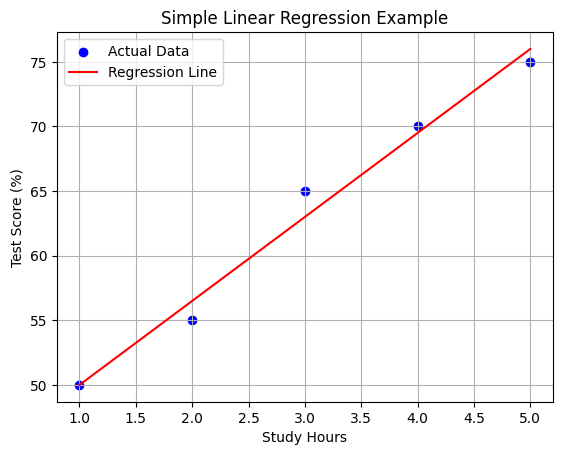

Slope (w): 6.50
Intercept (b): 43.50


In [6]:
# Simple dataset
X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)
y = np.array([50, 55, 65, 70, 75])

# Train Linear Regression Model
model = LinearRegression()
model.fit(X, y)

# Predictions
y_pred = model.predict(X)

# Plot
plt.scatter(X, y, color='blue', label='Actual Data')
plt.plot(X, y_pred, color='red', label='Regression Line')
plt.xlabel('Study Hours')
plt.ylabel('Test Score (%)')
plt.title('Simple Linear Regression Example')
plt.legend()
plt.grid(True)
plt.show()

# Print coefficients
print(f"Slope (w): {model.coef_[0]:.2f}")
print(f"Intercept (b): {model.intercept_:.2f}")


In [7]:
model.coef_

array([6.5])

# Housing Price Prediction

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Load dataset
data = pd.read_csv("Housing.csv")

# Separate features and target
X = data[["area", "bedrooms", "bathrooms", "stories"]]
y = data["price"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
X.shape

(545, 4)

In [10]:
y.shape

(545,)

In [11]:
X_train.shape

(436, 4)

In [12]:
y_train.shape

(436,)

In [13]:
X_test.shape

(109, 4)

In [14]:
y_test.shape

(109,)

In [15]:
X_train

,area,bedrooms,bathrooms,stories
46,6000,3,2,4
93,7200,3,2,1
335,3816,2,1,1
412,2610,3,1,2
471,3750,3,1,2
...,...,...,...,...
71,6000,4,2,4
106,5450,4,2,1
270,4500,3,2,3
435,4040,2,1,1


In [16]:
X_test

,area,bedrooms,bathrooms,stories
316,5900,4,2,2
77,6500,3,2,3
360,4040,2,1,1
90,5000,3,1,2
493,3960,3,1,1
...,...,...,...,...
15,6000,4,1,2
357,6930,4,1,2
39,6000,4,2,4
54,6000,3,2,2


In [17]:
# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

# Model parameters
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

MSE: 2457741642022.087
Coefficients: [3.49009738e+02 1.74685138e+05 1.25815095e+06 4.83859660e+05]
Intercept: -64342.420905679464


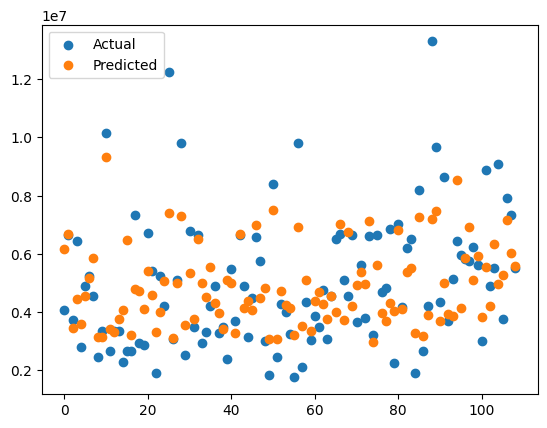

In [18]:
plt.scatter(range(len(y_test)), y_test, label="Actual")
plt.scatter(range(len(y_pred)), y_pred, label="Predicted")
plt.legend()
plt.show()


# Simple Example with PyTorch

In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
torch.manual_seed(42)

In [28]:
# Distances in miles for recent bike deliveries
distances = torch.tensor([[1.0], [2.0], [3.0], [4.0]], dtype=torch.float32)

# Corresponding delivery times in minutes
times = torch.tensor([[6.96], [12.11], [16.77], [22.21]], dtype=torch.float32)

# Create a model with one input (distance) and one output (time)
model = nn.Sequential(nn.Linear(1, 1))

# Define the loss function and optimizer
loss_function = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Training loop
for epoch in range(100):
    # Reset the optimizer's gradients
    optimizer.zero_grad()
    # Make predictions (forward pass)
    outputs = model(distances)
    # Calculate the loss
    loss = loss_function(outputs, times)
    # Calculate adjustments (backward pass)
    loss.backward()
    # Update the model's parameters
    optimizer.step()
    # Print loss every 50 epochs
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}: Loss = {loss.item()}")

Epoch 50: Loss = 0.026075642555952072
Epoch 100: Loss = 0.02590200863778591


In [23]:
# Access the first (and only) layer in the sequential model
layer = model[0]

# Get weights and bias
weights = layer.weight.data.numpy()
bias = layer.bias.data.numpy()

print(f"Weight: {weights}")
print(f"Bias: {bias}")

Weight: [[5.0382724]]
Bias: [1.9180175]


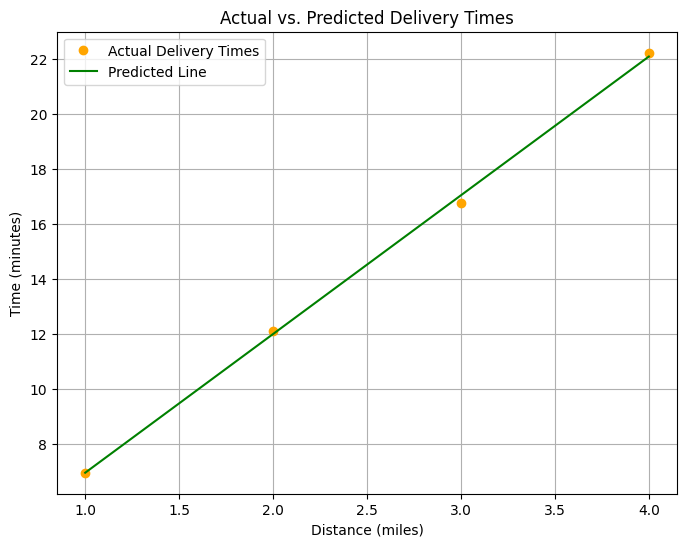

In [24]:
def plot_results(model, distances, times):
    """
    Plots the actual data points and the model's predicted line for a given dataset.

    Args:
        model: The trained machine learning model to use for predictions.
        distances: The input data points (features) for the model.
        times: The target data points (labels) for the plot.
    """
    # Set the model to evaluation mode
    model.eval()

    # Disable gradient calculation for efficient inference
    with torch.no_grad():
        # Make predictions using the trained model
        predicted_times = model(distances)

    # Create a new figure for the plot
    plt.figure(figsize=(8, 6))

    # Plot the actual data points
    plt.plot(distances.numpy(), times.numpy(), color='orange', marker='o', linestyle='None', label='Actual Delivery Times')

    # Plot the predicted line from the model
    plt.plot(distances.numpy(), predicted_times.numpy(), color='green', marker='None', label='Predicted Line')

    # Set the title of the plot
    plt.title('Actual vs. Predicted Delivery Times')
    # Set the x-axis label
    plt.xlabel('Distance (miles)')
    # Set the y-axis label
    plt.ylabel('Time (minutes)')
    # Display the legend
    plt.legend()
    # Add a grid to the plot
    plt.grid(True)
    # Show the plot
    plt.show()
plot_results(model, distances, times)

In [25]:
distance_to_predict = 7.0

In [27]:
# Use the torch.no_grad() context manager for efficient predictions
with torch.no_grad():
    # Convert the Python variable into a 2D PyTorch tensor that the model expects
    new_distance = torch.tensor([[distance_to_predict]], dtype=torch.float32)

    # Pass the new data to the trained model to get a prediction
    predicted_time = model(new_distance)

    # Use .item() to extract the scalar value from the tensor for printing
    print(f"Prediction for a {distance_to_predict}-mile delivery: {predicted_time.item():.1f} minutes")

    # Use the scalar value in a conditional statement to make the final decision
    if predicted_time.item() > 30:
        print("\nDecision: Do NOT take the job. You will likely be late.")
    else:
        print("\nDecision: Take the job. You can make it!")

Prediction for a 7.0-mile delivery: 37.2 minutes

Decision: Do NOT take the job. You will likely be late.
